In [13]:
"""
Fitness Tracker Analysis (fitness_tracker.csv, 365 days)
Question: “Does being active improve sleep, and is the user losing weight?”

1:Convert date to datetime and fill the missing steps.
2:Add a 7-day rolling average of steps and weight.
3:Compare weekdays and weekends with a groupby.
4:Plot weight over time and mark the trend line.
5:Make a correlation heatmap and a box plot of calories by workout type.
6:Write a conclusion on whether the user hit a 10,000 steps goal.
"""

'\nFitness Tracker Analysis (fitness_tracker.csv, 365 days)\nQuestion: “Does being active improve sleep, and is the user losing weight?”\n\n1:Convert date to datetime and fill the missing steps.\n2:Add a 7-day rolling average of steps and weight.\n3:Compare weekdays and weekends with a groupby.\n4:Plot weight over time and mark the trend line.\n5:Make a correlation heatmap and a box plot of calories by workout type.\n6:Write a conclusion on whether the user hit a 10,000 steps goal.\n'

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [15]:
df=pd.read_csv('/content/fitness_tracker.csv')

In [16]:
df
df.isna().sum()

,0
date,0
steps,15
active_minutes,0
calories_burned,0
sleep_hours,0
weight_kg,0
workout_type,0


In [17]:
#Task 1
df['date'] = pd.to_datetime(df['date'])



df['steps'] = df['steps'].fillna(df['steps'].median())



In [18]:
df.isna().sum()

,0
date,0
steps,0
active_minutes,0
calories_burned,0
sleep_hours,0
weight_kg,0
workout_type,0


In [19]:
#Task 2 Add a 7-day rolling average of steps and weight.
df["step_7d"]=df["steps"].rolling(7).mean()
df["weight_7d"]=df['weight_kg'].rolling(7).mean()

In [20]:
#Task 3 Compare weekdays and weekends with a groupby.
df["day_type"]=np.where(df["date"].dt.dayofweek>=5,"Weekend","Weekday")


In [21]:
df.groupby("day_type")[["steps","active_minutes","calories_burned","sleep_hours"]].mean().round(1)

,steps,active_minutes,calories_burned,sleep_hours
day_type,,,,
Weekday,7875.7,52.5,2118.0,7.0
Weekend,9693.4,65.9,2188.8,7.6


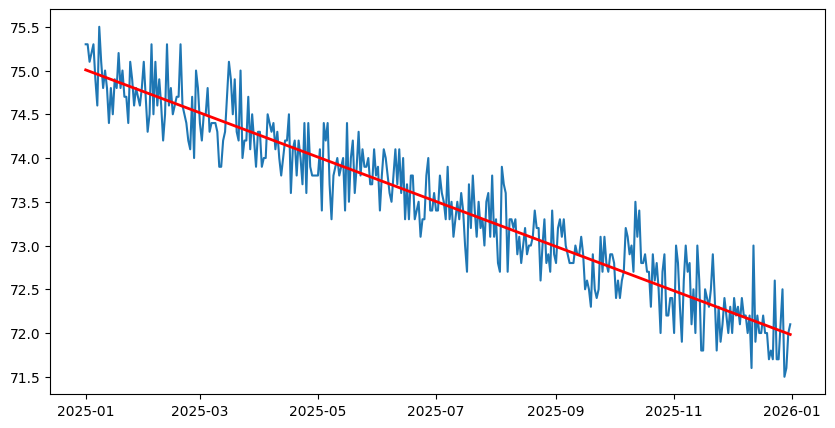

In [22]:
#4:Plot weight over time and mark the trend line.

x=np.arange(len(df))
slope,intercept=np.polyfit(x,df["weight_kg"],1)
plt.figure(figsize=(10,5))
plt.plot(df["date"],df["weight_kg"],label="Daily Weight")
plt.plot(df["date"],slope*x+intercept,color="red",linewidth=2)

In [25]:
df

,date,steps,active_minutes,calories_burned,sleep_hours,weight_kg,workout_type,step_7d,weight_7d,day_type
0,2025-01-01,4735.0,32.0,1970.0,8.9,75.3,Walk,NaN,NaN,Weekday
1,2025-01-02,9020.0,65.0,2254.0,8.7,75.3,Run,NaN,NaN,Weekday
2,2025-01-03,8346.0,53.0,2047.0,7.7,75.1,Gym,NaN,NaN,Weekday
3,2025-01-04,9458.0,64.0,2013.0,7.9,75.2,Walk,NaN,NaN,Weekend
4,2025-01-05,13088.0,85.0,2382.0,8.4,75.3,Walk,NaN,NaN,Weekend
...,...,...,...,...,...,...,...,...,...,...
360,2025-12-27,9042.0,59.0,2292.0,8.8,72.5,Run,5438.000000,72.014286,Weekend
361,2025-12-28,10605.0,62.0,2166.0,8.0,71.5,Walk,6048.428571,71.971429,Weekend
362,2025-12-29,9624.0,57.0,2124.0,7.0,71.6,Gym,6559.571429,71.957143,Weekday
363,2025-12-30,7958.0,47.0,2205.0,7.6,72.0,Rest,7079.142857,71.871429,Weekday


<Axes: xlabel='workout_type', ylabel='calories_burned'>

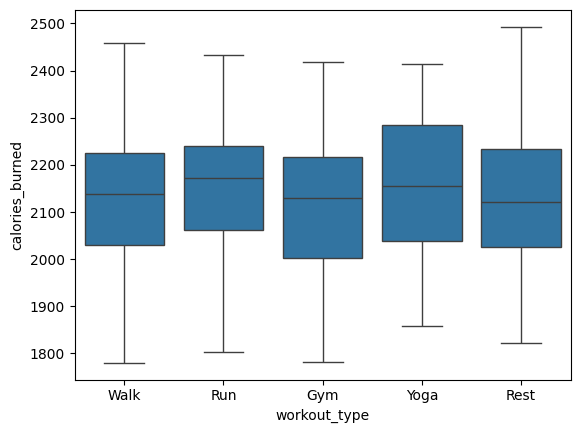

In [28]:
#Make a correlation heatmap and a box plot of calories by workout type.
cols=["weight_kg","steps","active_minutes","calories_burned","sleep_hours"]

#sns.heatmap(df[cols].corr(),annot=True)

sns.boxplot(data=df,x="workout_type",y="calories_burned")

In [31]:
#6:Write a conclusion on whether the user hit a 10,000 steps goal.
goal_days=(df["steps"]>=10000).sum()
goal_days
print(f"Goal met on {goal_days} of {len(df)} days ({goal_days/len(df)*100:.1f}%)")

print("Average steps : ",round(df["steps"].mean()))

Goal met on 100 of 365 days (27.4%)
Average steps :  8394
